# Taller — Construye y ajusta tu propio clasificador de imágenes

Este taller comienza **después de la teoría de CNN y del notebook guiado de transfer learning**.

La meta no es memorizar la API de Keras. La meta es tomar decisiones sobre un problema real: construir datos propios, adaptar un modelo preentrenado y analizar qué tan bien funciona.

---

## Organización de la actividad

| Momento | Tiempo estimado | Meta |
|---|---:|---|
| **Teoría + notebook guiado** | Se realiza antes de este taller | Comprender CNN, transfer learning y fine-tuning |
| **Trabajo en clase** | ~60 min | Construir el dataset y entrenar el primer modelo con la base congelada |
| **Trabajo en casa** | ~1–2 h | Evaluar, hacer fine-tuning, comparar y analizar errores |

### Regla importante

Durante el trabajo en clase usaremos **train** y **validation**.  
El conjunto de **test** se reservará para el trabajo en casa, cuando hagamos la evaluación final.

---

## Entrega final

Debes entregar **este mismo notebook ejecutado**, incluyendo:

- definición del problema y estrategia de búsqueda;
- dataset propio;
- primer entrenamiento con transfer learning;
- evaluación en test;
- fine-tuning;
- comparación antes/después;
- matriz de confusión;
- análisis de al menos 5 errores;
- conclusiones.

## 0. Preparación del entorno

La búsqueda de imágenes se realizará con `ddgs`. Si estás en Google Colab, ejecuta la siguiente celda.

In [1]:
!pip -q install -U ddgs

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.6/47.6 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 63.2 MB/s eta 0:00:00


In [2]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

from pathlib import Path
import hashlib, io, random, shutil, time
import numpy as np
import matplotlib.pyplot as plt
import requests
from PIL import Image

import tensorflow as tf
import keras
from keras import layers
from ddgs import DDGS
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Keras:", keras.__version__)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

Keras: 3.13.2
TensorFlow: 2.21.0
GPU: []


# PARTE A — TRABAJO EN CLASE (~60 min)

## Objetivo de esta parte

Antes de terminar la sesión debes haber conseguido:

1. definir un problema de clasificación de 3 clases;
2. descargar y revisar un dataset propio;
3. separar los datos en `train`, `validation` y `test`;
4. cargar EfficientNetB0 preentrenada en ImageNet;
5. congelar el backbone;
6. entrenar una nueva cabeza de clasificación;
7. observar `accuracy` y `val_accuracy`.

> **No evalúes todavía sobre `test`.** Ese conjunto queda reservado para el trabajo en casa.

### Distribución sugerida

- **10 min** — problema y términos de búsqueda;
- **20 min** — descarga, inspección y limpieza;
- **10 min** — separación y carga del dataset;
- **20 min** — transfer learning y primer entrenamiento.

# 1. Define tu problema — EN CLASE

Elige un problema de clasificación de **3 clases**. Las clases deben ser visualmente distinguibles.

Ejemplos: `espresso/cappuccino/latte`, `bus/motorcycle/bicycle`, tres especies de flores, frutas, tipos de calzado o instrumentos musicales.

Evita problemas donde la clase dependa de información que no aparece visualmente en la imagen.

## TODO 1 — Problema y estrategia de búsqueda

Define:

1. las tres clases;
2. dos o tres términos de búsqueda por clase;
3. una breve hipótesis: **¿qué características visuales esperas que use el modelo?**;
4. un posible sesgo o fuente de *data leakage* que podría aparecer al descargar imágenes desde un buscador.

In [3]:
# TODO 1 — EN CLASE: define tus clases y búsquedas
SEARCHES = {
    "bus": [
        "city bus on street",
        "public transport bus photo",
        "autobus urbano en la calle",
    ],
    "motorcycle": [
        "motorcycle on road",
        "motorbike photo",
        "motocicleta en la calle",
    ],
    "bicycle": [
        "bicycle on street",
        "city bike photo",
        "bicicleta en la calle",
    ],
}

SEARCHES


{'bus': ['city bus on street',
  'public transport bus photo',
  'autobus urbano en la calle'],
 'motorcycle': ['motorcycle on road',
  'motorbike photo',
  'motocicleta en la calle'],
 'bicycle': ['bicycle on street', 'city bike photo', 'bicicleta en la calle']}

### Antes de descargar

Escribe debajo de esta celda una respuesta corta:

- ¿Qué características visuales esperas que diferencien tus clases?
- ¿Qué imágenes incorrectas esperas encontrar?
- ¿Qué sesgo o *data leakage* podría aparecer?

**Respuesta (antes de descargar):**

- **Características visuales esperadas.** *Bus:* silueta grande y rectangular, fila de ventanas, ruedas grandes bajo una carrocería alta. *Motocicleta:* manubrio, tanque y motor visibles, dos ruedas gruesas, con frecuencia un conductor con casco. *Bicicleta:* marco de tubos delgados, ruedas finas con radios, pedales y ausencia de motor. Espero que el modelo use sobre todo **forma global y tamaño relativo** (bus vs. dos ruedas) y **detalles de estructura** (motor/tanque vs. marco delgado) para separar moto de bicicleta.
- **Imágenes incorrectas que espero encontrar.** Scooters y ciclomotores (frontera entre moto y bicicleta), bicicletas estáticas de gimnasio, camiones o carros en la búsqueda de bus, ilustraciones, logos e íconos vectoriales, buses de juguete, banners publicitarios con texto y fotos de tienda donde el objeto aparece diminuto.
- **Sesgo / data leakage posible.** (1) *Fondo correlacionado con la clase:* los buses suelen salir en calle o terminal, las bicicletas en ciclovías o parques y las motos de catálogo sobre fondo blanco; el modelo podría aprender el fondo y no el objeto. (2) *Duplicados casi idénticos:* el hash SHA-256 solo elimina copias **exactas**; la misma foto con otro tamaño, recorte o marca de agua pasa el filtro y puede caer en `train` y en `test`, inflando el accuracy. (3) *Estilo por término de búsqueda:* "photo" frente a "en la calle" atrae estilos distintos, y si una clase viene de pocas fuentes el modelo aprende la fuente.

# 2. Buscar y descargar imágenes — EN CLASE

La siguiente función busca imágenes y descarga los resultados. Intenta ignorar URLs fallidas, verificar las imágenes, evitar duplicados exactos con un hash y convertirlas a RGB.

> Se solicita contenido con licencia Creative Commons cuando el motor lo soporta. Eso no sustituye la revisión de licencias si el dataset se va a redistribuir.

In [4]:
RAW_DIR = Path("data_raw")
RAW_DIR.mkdir(exist_ok=True)

def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def download_image_dataset(searches, root=RAW_DIR, images_per_query=60, min_side=120, timeout=8):
    session = requests.Session()
    session.headers.update({"User-Agent": "Mozilla/5.0"})

    # Incluye imágenes de ejecuciones anteriores para que volver a ejecutar
    # la descarga no agregue duplicados exactos al dataset.
    seen_hashes = {
        file_sha256(path)
        for path in Path(root).glob("*/*.jpg")
        if path.is_file()
    }

    for class_name, queries in searches.items():
        class_dir = root / class_name
        class_dir.mkdir(parents=True, exist_ok=True)
        saved = len(list(class_dir.glob("*.jpg")))
        print(f"\n=== {class_name} ===")

        for query in queries:
            print(f"Buscando: {query!r}")
            try:
                results = DDGS().images(
                    query=query,
                    safesearch="moderate",
                    max_results=images_per_query,
                    license_image="any",
                )
            except Exception as e:
                print("  Error en búsqueda:", e)
                continue

            for result in results:
                url = result.get("image")
                if not url:
                    continue
                try:
                    response = session.get(url, timeout=timeout)
                    response.raise_for_status()
                    data = response.content
                    digest = hashlib.sha256(data).hexdigest()
                    if digest in seen_hashes:
                        continue

                    with Image.open(io.BytesIO(data)) as img:
                        img = img.convert("RGB")
                        if min(img.size) < min_side:
                            continue
                        filename = class_dir / f"{saved:04d}.jpg"
                        img.save(filename, format="JPEG", quality=90)

                    seen_hashes.add(digest)
                    saved += 1
                except Exception:
                    pass

            print(f"  Total guardadas hasta ahora: {saved}")
            time.sleep(1)

    print("\nDescarga terminada.")

## TODO 2 — EN CLASE: construye y limpia tu dataset

Tu objetivo inicial es obtener aproximadamente **100–150 imágenes útiles por clase**.

1. Ejecuta la descarga.
2. Inspecciona muestras aleatorias.
3. Mejora los términos de búsqueda si una clase trae resultados pobres.
4. Elimina imágenes claramente incorrectas o problemáticas.
5. Reporta el número final de imágenes por clase y describe el error más frecuente que encontraste.

> Si la búsqueda trae datos malos, **no aumentes simplemente `max_results`**. Primero mejora los términos de búsqueda.

In [5]:
# TODO 2 — EN CLASE: ejecuta la descarga con tus búsquedas
download_image_dataset(
    SEARCHES,
    images_per_query=60,
)


=== bus ===
Buscando: 'city bus on street'
  Total guardadas hasta ahora: 34
Buscando: 'public transport bus photo'
  Total guardadas hasta ahora: 65
Buscando: 'autobus urbano en la calle'
  Total guardadas hasta ahora: 95

=== motorcycle ===
Buscando: 'motorcycle on road'
  Total guardadas hasta ahora: 35
Buscando: 'motorbike photo'
  Total guardadas hasta ahora: 70
Buscando: 'motocicleta en la calle'
  Total guardadas hasta ahora: 102

=== bicycle ===
Buscando: 'bicycle on street'
  Total guardadas hasta ahora: 31
Buscando: 'city bike photo'
  Total guardadas hasta ahora: 64
Buscando: 'bicicleta en la calle'
  Total guardadas hasta ahora: 96

Descarga terminada.


In [6]:
def count_images(root):
    counts = {}
    for folder in sorted(Path(root).iterdir()):
        if folder.is_dir():
            counts[folder.name] = len(list(folder.glob("*.jpg")))
    return counts

count_images(RAW_DIR)

{'bicycle': 96, 'bus': 95, 'motorcycle': 102}

## Validación técnica automática de las imágenes

Antes de inspeccionar el contenido del dataset, comprobaremos que **TensorFlow pueda decodificar todas las imágenes**.

Esto resuelve un problema distinto al de la inspección visual:

- **Validación técnica:** ¿el archivo puede ser leído correctamente por TensorFlow?
- **Validación semántica:** ¿la imagen realmente pertenece a la clase indicada?

Una imagen puede abrirse aparentemente bien en otras librerías y aun así fallar durante `model.fit()`. Por eso hacemos esta comprobación usando el mismo decoder que utilizará el pipeline de Keras.

In [7]:
def remove_invalid_images(root_dir):
    root_dir = Path(root_dir)
    bad_files = []

    for path in root_dir.rglob("*.jpg"):
        try:
            raw = tf.io.read_file(str(path))

            img = tf.io.decode_image(
                raw,
                channels=3,
                expand_animations=False,
            )

            # Forzamos la ejecución para detectar errores de decodificación.
            _ = img.numpy()

        except Exception as e:
            print("Imagen inválida:", path)
            print(" ", str(e).splitlines()[0])
            bad_files.append(path)

    for path in bad_files:
        path.unlink(missing_ok=True)

    print(f"\nImágenes inválidas eliminadas: {len(bad_files)}")

    return bad_files


bad_files = remove_invalid_images(RAW_DIR)


Imágenes inválidas eliminadas: 0


### Verificación

Ejecuta nuevamente la función. El resultado esperado es:

```text
Imágenes inválidas eliminadas: 0
```

Si todavía aparece alguna imagen inválida, vuelve a ejecutar hasta obtener cero antes de continuar.

In [8]:
bad_files = remove_invalid_images(RAW_DIR)

assert len(bad_files) == 0, (
    "Todavía quedan imágenes que TensorFlow no puede decodificar."
)

print("✓ Todas las imágenes pueden ser decodificadas por TensorFlow.")


Imágenes inválidas eliminadas: 0
✓ Todas las imágenes pueden ser decodificadas por TensorFlow.


# 3. Inspección y limpieza semántica — EN CLASE

La etapa anterior confirmó que los archivos son **técnicamente válidos**.

Ahora viene una tarea diferente: comprobar si los datos son **semánticamente correctos**.

Busca especialmente:

- imágenes que no correspondan a la clase;
- dibujos, logos o diagramas si tu objetivo son fotografías;
- imágenes con texto que pueda revelar artificialmente la etiqueta;
- duplicados o imágenes casi idénticas;
- fondos que estén correlacionados con una clase;
- diferencias sistemáticas de estilo o calidad entre clases.

> Que TensorFlow pueda abrir una imagen no significa que sea un buen dato de entrenamiento.

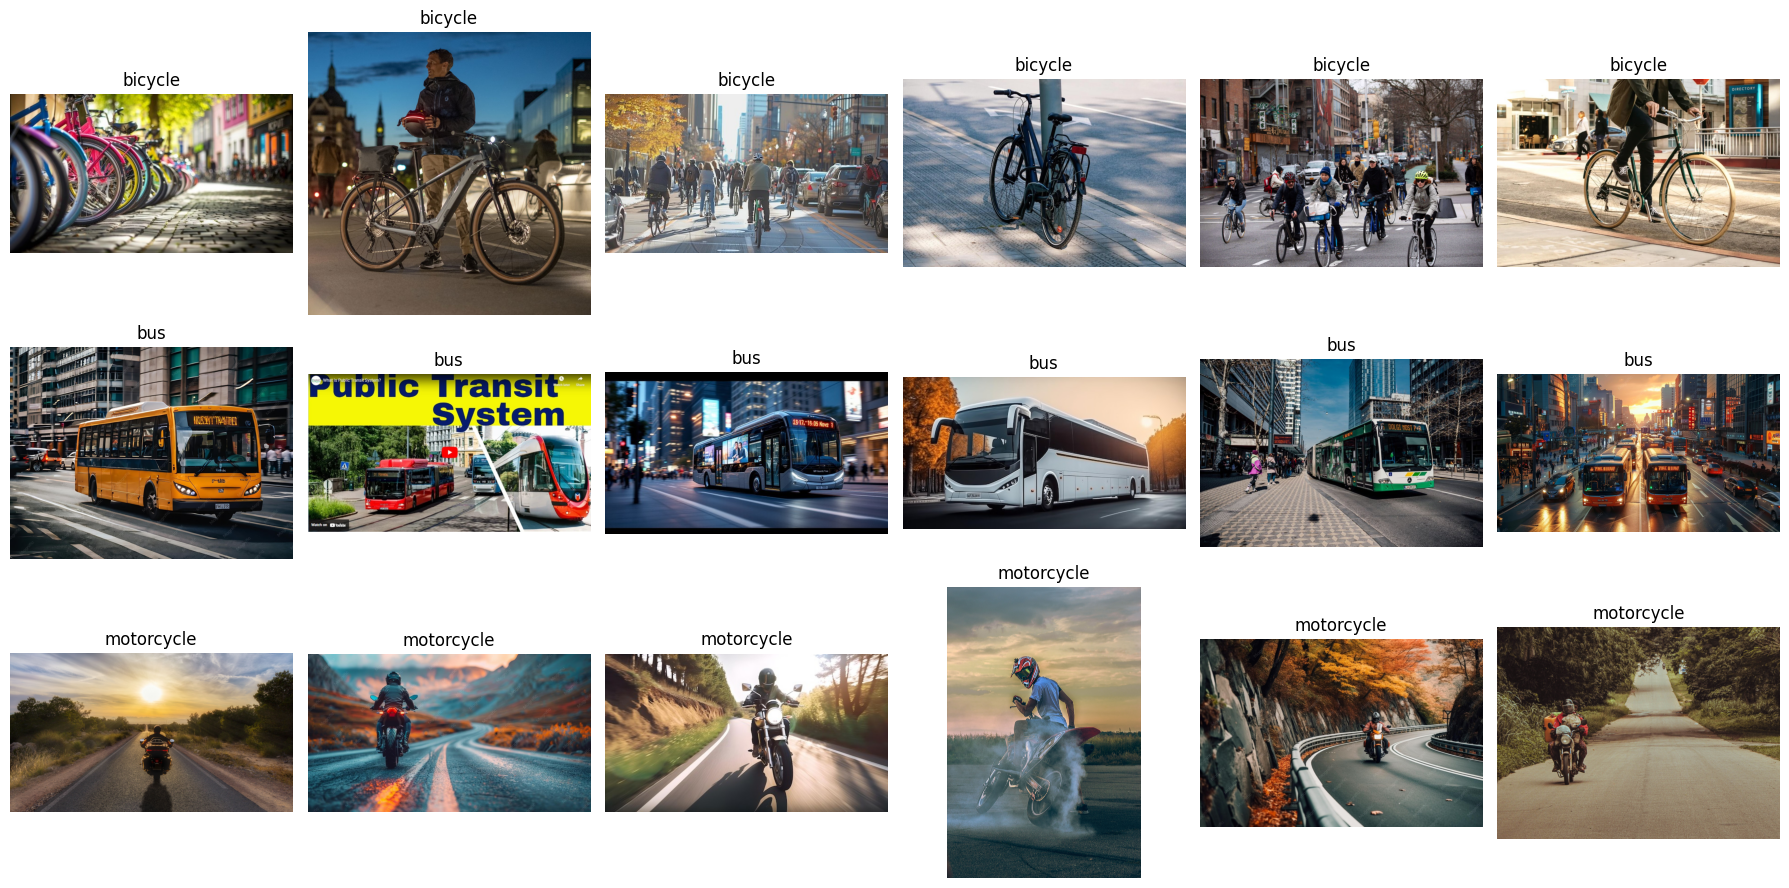

In [9]:
def show_random_images(root, n_per_class=6):
    root = Path(root)
    class_dirs = [p for p in sorted(root.iterdir()) if p.is_dir()]
    fig, axes = plt.subplots(len(class_dirs), n_per_class, figsize=(3*n_per_class, 3*len(class_dirs)))
    if len(class_dirs) == 1:
        axes = np.expand_dims(axes, 0)
    for row, class_dir in enumerate(class_dirs):
        files = list(class_dir.glob("*.jpg"))
        chosen = random.sample(files, min(n_per_class, len(files)))
        for col in range(n_per_class):
            ax = axes[row, col]
            if col < len(chosen):
                img = Image.open(chosen[col])
                ax.imshow(img)
                ax.set_title(class_dir.name)
            ax.axis("off")
    plt.tight_layout()

show_random_images(RAW_DIR)

### Checkpoint del dataset

Antes de continuar, asegúrate de que:

- cada carpeta contiene imágenes realmente asociadas a su clase;
- no predominan logos, dibujos o texto que revele la etiqueta;
- no hay una diferencia de fondo/estilo demasiado obvia entre clases;
- el número de imágenes por clase es razonablemente balanceado.

Registra aquí el número de imágenes eliminadas y el problema de calidad más frecuente.

In [10]:
# Registro del checkpoint: tamaño y balance del dataset después de la limpieza
from IPython.display import Markdown, display

counts = count_images(RAW_DIR)
total = sum(counts.values())
balance = min(counts.values()) / max(counts.values()) if total else 0.0
display(Markdown(
    "**Imágenes por clase (después de limpiar):** "
    + ", ".join(f"{k} = **{v}**" for k, v in counts.items())
    + f"  \n**Total:** {total}  |  **Balance** (clase menor / clase mayor): **{balance:.2f}**"
    + ("  → razonablemente balanceado." if balance >= 0.8 else "  → conviene rebalancear (descargar más de la clase pequeña con mejores términos).")
))


**Imágenes por clase (después de limpiar):** bicycle = **96**, bus = **95**, motorcycle = **102**  
**Total:** 293  |  **Balance** (clase menor / clase mayor): **0.93**  → razonablemente balanceado.

**Registro de limpieza** (✏️ *completa estas dos líneas después de inspeccionar tus imágenes; la celda anterior ya imprime los conteos finales*):

- Imágenes eliminadas en la limpieza semántica: **✏️ ___** (más las inválidas que quitó `remove_invalid_images`).
- Problema de calidad más frecuente: **✏️ ___**. Lo más probable en este problema es la confusión de la clase `motorcycle` con scooters y bicicletas eléctricas, y la aparición de ilustraciones o imágenes con texto en la clase `bus`; si es lo que viste, descríbelo así con un ejemplo concreto.

# 4. Separar train, validation y test — EN CLASE

> **Concepto clave — tres conjuntos, tres funciones**
>
> - **Train:** se utiliza para actualizar los pesos del modelo.
> - **Validation:** se utiliza durante el desarrollo para decidir épocas, `learning_rate`, número de capas a descongelar, etc.
> - **Test:** se reserva para medir el rendimiento final. No debe guiar las decisiones de entrenamiento.

Usaremos **70 % entrenamiento, 15 % validación y 15 % prueba**.

In [11]:
SPLIT_DIR = Path("dataset")

def split_dataset(source_root, destination_root, train_ratio=0.70, val_ratio=0.15, seed=SEED):
    source_root = Path(source_root)
    destination_root = Path(destination_root)
    if destination_root.exists():
        shutil.rmtree(destination_root)
    rng = random.Random(seed)

    for class_dir in sorted(source_root.iterdir()):
        if not class_dir.is_dir():
            continue
        files = list(class_dir.glob("*.jpg"))
        rng.shuffle(files)
        n = len(files)
        n_train = int(n * train_ratio)
        n_val = int(n * val_ratio)
        splits = {
            "train": files[:n_train],
            "validation": files[n_train:n_train+n_val],
            "test": files[n_train+n_val:],
        }
        for split_name, split_files in splits.items():
            target = destination_root / split_name / class_dir.name
            target.mkdir(parents=True, exist_ok=True)
            for src in split_files:
                shutil.copy2(src, target / src.name)

split_dataset(RAW_DIR, SPLIT_DIR)
for split in ["train", "validation", "test"]:
    print(split, count_images(SPLIT_DIR / split))

train {'bicycle': 67, 'bus': 66, 'motorcycle': 71}
validation {'bicycle': 14, 'bus': 14, 'motorcycle': 15}
test {'bicycle': 15, 'bus': 15, 'motorcycle': 16}


### Comprobación conceptual

Explica brevemente: ¿por qué usar repetidamente el conjunto de prueba para escoger épocas, `learning_rate` o capas a descongelar termina contaminando nuestra estimación de desempeño?

**Respuesta:** Porque en cuanto el conjunto de prueba **guía una decisión** (cuántas épocas, qué `learning_rate`, cuántas capas descongelar), deja de ser un dato "no visto" y pasa a formar parte del proceso de selección. Cada vez que escogemos la configuración que mejor puntúa en `test`, ajustamos la elección al **ruido particular** de esas imágenes: el modelo elegido es el que tuvo suerte en ese conjunto. El accuracy final queda **optimista** y ya no estima el desempeño sobre datos nuevos (es un *overfitting indirecto* al test). Con conjuntos de prueba pequeños, como los de este taller (unas decenas de imágenes), una sola imagen mueve varios puntos de accuracy y el efecto se agrava. Por eso las decisiones se toman con `validation` y `test` se usa **una sola vez**, al final.

# 5. Construir los datasets de Keras — EN CLASE

`image_dataset_from_directory()` construye un `tf.data.Dataset` usando el nombre de las carpetas como clases.

Observa que:

- `train` se mezcla (`shuffle=True`);
- `validation` y `test` mantienen un orden estable;
- todas las imágenes se redimensionan a `224×224` para EfficientNetB0.

In [12]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "train", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=True, seed=SEED)
val_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "validation", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)
test_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "test", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)

test_file_paths = list(test_ds.file_paths)   # se guarda antes del prefetch (lo usa el análisis de errores)
class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)
print(class_names)

Found 204 files belonging to 3 classes.
Found 43 files belonging to 3 classes.
Found 46 files belonging to 3 classes.
['bicycle', 'bus', 'motorcycle']


# 6. Primer modelo: transfer learning — EN CLASE

Usaremos **EfficientNetB0** preentrenada en ImageNet. Primero congelaremos completamente la red base y entrenaremos solo una nueva cabeza de clasificación.

> **Concepto clave — Data augmentation**
>
> `RandomFlip`, `RandomRotation` y `RandomZoom` generan variaciones plausibles durante el entrenamiento. No crean información nueva, pero ayudan a que el modelo dependa menos de detalles accidentales de las imágenes descargadas.

> **Concepto clave — GlobalAveragePooling2D**
>
> En lugar de aplanar todos los mapas de características con `Flatten`, `GlobalAveragePooling2D` resume cada canal en un solo valor. Así reducimos mucho el número de parámetros de la cabeza de clasificación.

In [13]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
], name="augmentation")

base_model = keras.applications.EfficientNetB0(
    include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3))
base_model.trainable = False

inputs = keras.Input(shape=(*IMG_SIZE, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = keras.Model(inputs, outputs)
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## TODO 3 — EN CLASE: entrena la cabeza de clasificación

La base EfficientNet está congelada. Tu trabajo es configurar y entrenar la nueva cabeza.

> **Concepto clave — EarlyStopping**
>
> `EarlyStopping` detiene el entrenamiento cuando `val_loss` deja de mejorar. Con `restore_best_weights=True`, Keras recupera los pesos de la mejor época observada en validación.

Antes de ejecutar, escribe una predicción corta:

- ¿esperas que `train_accuracy` suba rápidamente?
- ¿qué señal en las curvas indicaría overfitting?

Completa únicamente los espacios `TODO` del código siguiente.

**Predicción antes de ejecutar:**

- **¿Sube `train_accuracy` rápidamente?** Sí, debería subir en pocas épocas. EfficientNetB0 ya trae de ImageNet características muy útiles (bordes, texturas, partes de objetos) y solo se entrena la capa final `Dense(3)`, con 1280·3 + 3 = **3,843 parámetros**. Un detalle: como `data_augmentation` y `Dropout` solo actúan en entrenamiento, es normal que `val_accuracy` iguale o supere a `train_accuracy` en las primeras épocas.
- **Señal de overfitting:** `val_loss` se estanca o sube mientras `train_loss` sigue bajando, y la brecha entre `accuracy` y `val_accuracy` se ensancha época tras época. `EarlyStopping` está para cortar justo ahí.

In [14]:
# TODO 3 — EN CLASE: completa la configuración de entrenamiento

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),  # 1e-3
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],                                 # "accuracy"
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",            # "val_loss"
    patience=2,
    restore_best_weights=True,
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping],
)


Epoch 1/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 46s 5s/step - accuracy: 0.3725 - loss: 1.1306 - val_accuracy: 0.8605 - val_loss: 0.7382
Epoch 2/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 24s 3s/step - accuracy: 0.8186 - loss: 0.6447 - val_accuracy: 0.9070 - val_loss: 0.4543
Epoch 3/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 39s 3s/step - accuracy: 0.9216 - loss: 0.4032 - val_accuracy: 0.9302 - val_loss: 0.3178
Epoch 4/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 42s 3s/step - accuracy: 0.9461 - loss: 0.2918 - val_accuracy: 0.9302 - val_loss: 0.2303
Epoch 5/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 23s 3s/step - accuracy: 0.9363 - loss: 0.2331 - val_accuracy: 0.9302 - val_loss: 0.1870
Epoch 6/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 21s 3s/step - accuracy: 0.9706 - loss: 0.1957 - val_accuracy: 0.9302 - val_loss: 0.1629
Epoch 7/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 42s 3s/step - accuracy: 0.9755 - loss: 0.1489 - val_accuracy: 0.9302 - val_loss: 0.1513
Epoch 8/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 42s 3s/step - accuracy: 0.9853 - loss: 0.1340 - val_accuracy: 0.9302 - val_loss: 0.1400
Epoch 9/

### Curvas de aprendizaje — EN CLASE si el tiempo lo permite

Grafica `accuracy`, `val_accuracy`, `loss` y `val_loss`.

Si el tiempo de clase termina antes, **puedes completar estas curvas en casa**.  
Lo obligatorio antes de salir es haber entrenado el primer modelo y tener sus métricas de entrenamiento/validación.

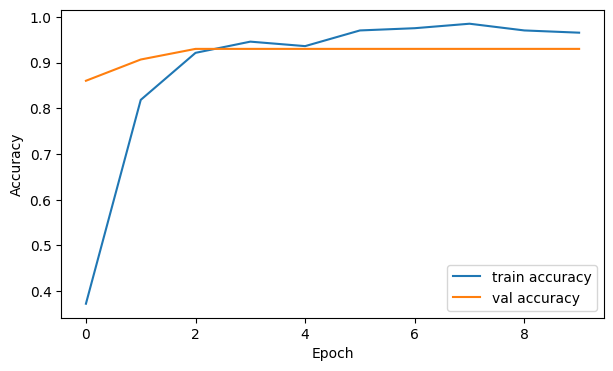

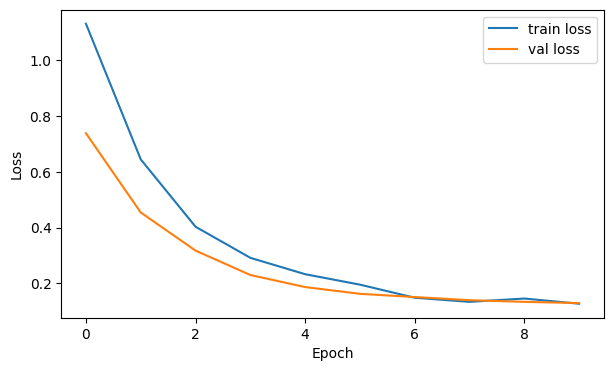

In [15]:
# Completa las cuatro curvas usando el objeto history
plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="train accuracy")
plt.plot(history.history["val_accuracy"], label="val accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()


In [16]:
# Lectura de las curvas con los números reales del primer entrenamiento
from IPython.display import Markdown, display

h = history.history
n_ep = len(h["loss"])
best_ep = int(np.argmin(h["val_loss"])) + 1
gap = h["accuracy"][-1] - h["val_accuracy"][-1]
display(Markdown(
    f"- Épocas ejecutadas: **{n_ep}** (de 10; `EarlyStopping` restauró los pesos de la época **{best_ep}**).\n"
    f"- Última época: `accuracy` = **{h['accuracy'][-1]:.3f}**, `val_accuracy` = **{h['val_accuracy'][-1]:.3f}** "
    f"(brecha train − val = {gap:+.3f}).\n"
    f"- Mejor `val_accuracy` = **{max(h['val_accuracy']):.3f}**; menor `val_loss` = **{min(h['val_loss']):.3f}**.\n"
    f"- **Lectura:** " + (
        "la validación acompaña al entrenamiento, sin señal clara de overfitting."
        if gap < 0.05 else
        "hay una brecha apreciable entre entrenamiento y validación: señal de overfitting."
    )
))


- Épocas ejecutadas: **10** (de 10; `EarlyStopping` restauró los pesos de la época **10**).
- Última época: `accuracy` = **0.966**, `val_accuracy` = **0.930** (brecha train − val = +0.035).
- Mejor `val_accuracy` = **0.930**; menor `val_loss` = **0.130**.
- **Lectura:** la validación acompaña al entrenamiento, sin señal clara de overfitting.

# PUNTO DE CONTROL — FIN DEL TRABAJO EN CLASE

Antes de continuar, verifica que tu equipo tenga:

- [ ] 3 clases definidas;
- [ ] términos de búsqueda documentados;
- [ ] imágenes descargadas;
- [ ] dataset inspeccionado y parcialmente limpiado;
- [ ] separación `train / validation / test`;
- [ ] EfficientNetB0 con pesos de ImageNet;
- [ ] backbone congelado;
- [ ] nueva cabeza de clasificación;
- [ ] al menos un entrenamiento completado;
- [ ] `accuracy` y `val_accuracy` reportadas.

## Hasta aquí llega el trabajo de clase.

**No uses todavía el conjunto de test para tomar decisiones.**

---

# PARTE B — TRABAJO EN CASA

A partir de este punto debes completar el análisis de manera autónoma.

Ahora sí vas a:

1. evaluar el modelo en `test`;
2. estudiar la matriz de confusión y métricas por clase;
3. realizar fine-tuning;
4. comparar el modelo congelado contra el modelo ajustado;
5. analizar errores;
6. escribir las conclusiones.

# 7. Evaluación del primer modelo — EN CASA

Ahora sí utilizaremos el conjunto de prueba.

> **Concepto clave — No todo es accuracy**
>
> - **Precision:** de las imágenes que el modelo predijo como una clase, ¿cuántas eran correctas?
> - **Recall:** de las imágenes que realmente pertenecían a una clase, ¿cuántas encontró?
> - **F1:** combina precision y recall.
> - **Matriz de confusión:** muestra qué clases se están confundiendo entre sí.

Guarda esta evaluación: será nuestra línea base antes del fine-tuning.

In [17]:
test_loss_before, test_acc_before = model.evaluate(test_ds, verbose=0)
print(f"Test accuracy antes del fine-tuning: {test_acc_before:.4f}")

Test accuracy antes del fine-tuning: 0.9565


              precision    recall  f1-score   support

     bicycle      0.933     0.933     0.933        15
         bus      1.000     1.000     1.000        15
  motorcycle      0.938     0.938     0.938        16

    accuracy                          0.957        46
   macro avg      0.957     0.957     0.957        46
weighted avg      0.957     0.957     0.957        46



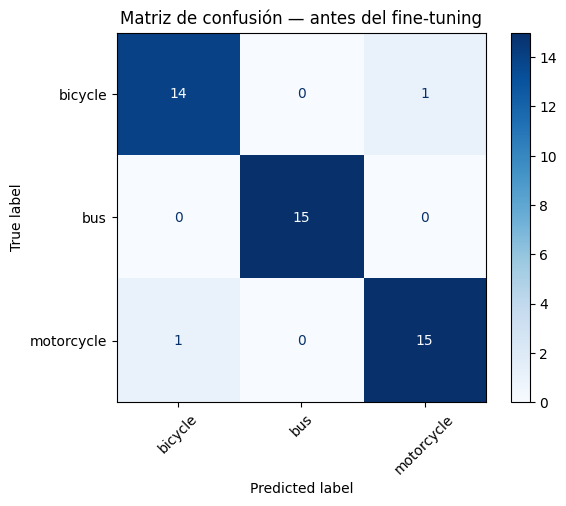

In [18]:
def get_predictions(model, dataset):
    y_true = np.concatenate([y.numpy() for _, y in dataset])
    probabilities = model.predict(dataset, verbose=0)
    y_pred = probabilities.argmax(axis=1)
    return y_true, y_pred, probabilities

y_true, y_pred, probabilities = get_predictions(model, test_ds)
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión — antes del fine-tuning")
plt.show()

## TODO 4 — EN CASA: interpreta la evaluación

Utilizando `classification_report` y la matriz de confusión, responde:

1. ¿Cuál clase obtuvo mejores resultados?
2. ¿Cuál fue la principal confusión?
3. ¿La accuracy global oculta algún problema por clase?
4. ¿Qué cambiarías primero en el **dataset** antes de cambiar el modelo?

In [19]:
# TODO 4 — Respuestas 1 a 3 calculadas con los resultados reales del primer modelo (línea base)
from IPython.display import Markdown, display
from sklearn.metrics import precision_recall_fscore_support

labels = list(range(NUM_CLASSES))
prec, rec, f1, sup = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)

best, worst = int(np.argmax(f1)), int(np.argmin(f1))
off = cm.copy(); np.fill_diagonal(off, 0)
i, j = np.unravel_index(off.argmax(), off.shape)
spread = rec.max() - rec.min()

txt  = f"**1. Mejor clase:** `{class_names[best]}` (F1 = {f1[best]:.3f}; la más débil es `{class_names[worst]}`, F1 = {f1[worst]:.3f}).\n\n"
if off.max() == 0:
    txt += "**2. Principal confusión:** no hubo confusiones en test (matriz diagonal).\n\n"
else:
    txt += (f"**2. Principal confusión:** imágenes reales de `{class_names[i]}` predichas como `{class_names[j]}` "
            f"({off[i, j]} de {sup[i]} en esa clase).\n\n")
txt += (f"**3. ¿La accuracy global oculta algo?** Accuracy global = {test_acc_before:.3f}; el recall por clase va de "
        f"{rec.min():.3f} (`{class_names[int(np.argmin(rec))]}`) a {rec.max():.3f} (`{class_names[int(np.argmax(rec))]}`). "
        + ("**Sí:** hay una clase claramente más débil que el promedio. " if spread > 0.10 else "No de forma apreciable: las clases rinden de manera parecida. ")
        + f"Ojo con el tamaño del test: {int(sup.sum())} imágenes, así que cada imagen vale ≈ {100/sup.sum():.1f} puntos de accuracy.")
display(Markdown(txt))


**1. Mejor clase:** `bus` (F1 = 1.000; la más débil es `bicycle`, F1 = 0.933).

**2. Principal confusión:** imágenes reales de `bicycle` predichas como `motorcycle` (1 de 15 en esa clase).

**3. ¿La accuracy global oculta algo?** Accuracy global = 0.957; el recall por clase va de 0.933 (`bicycle`) a 1.000 (`bus`). No de forma apreciable: las clases rinden de manera parecida. Ojo con el tamaño del test: 46 imágenes, así que cada imagen vale ≈ 2.2 puntos de accuracy.

**4. ¿Qué cambiaría primero en el dataset antes de cambiar el modelo?**

**Respuesta:** Atacaría la **calidad de las etiquetas y la diversidad** antes de tocar la arquitectura, en este orden: (1) quitar las imágenes mal etiquetadas o ambiguas (scooters en `motorcycle`, bicicletas eléctricas, ilustraciones y logos); (2) eliminar duplicados **casi idénticos**, que pueden estar repartidos entre `train` y `test` e inflar el resultado; (3) rebalancear la clase más pequeña con mejores términos de búsqueda (no con un `max_results` más alto); y (4) aumentar la variedad de fondos, ángulos y distancias, para que el modelo no se apoye en el contexto (calle, ciclovía, fondo blanco de catálogo). Un modelo mejor sobre datos sucios solo aprende más rápido los mismos errores.

# 8. Fine-tuning — EN CASA

Ahora permitiremos que una pequeña parte de EfficientNet se adapte al nuevo problema.

> **Concepto clave — Fine-tuning**
>
> En la fase anterior, los pesos del backbone no cambiaron. Ahora descongelaremos únicamente una parte final del modelo y la actualizaremos con un **learning rate mucho menor**.

> **Concepto clave — Batch Normalization**
>
> EfficientNet contiene capas `BatchNormalization`, que mantienen estadísticas internas aprendidas durante el entrenamiento. En datasets pequeños conviene mantenerlas congeladas durante fine-tuning para evitar actualizaciones inestables de esas estadísticas.

Después de cambiar qué capas son entrenables, es necesario **recompilar** el modelo.

In [20]:
base_model.trainable = True

# TODO 5 — Decide cuántas capas finales adaptar.
# Empieza con ~20. Puedes justificar otro valor usando validation.
N_UNFROZEN = 20

for layer in base_model.layers[:-N_UNFROZEN]:
    layer.trainable = False

# Mantener Batch Normalization congelado.
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print(
    "Capas entrenables de la base:",
    sum(layer.trainable for layer in base_model.layers),
    "/",
    len(base_model.layers),
)

Capas entrenables de la base: 15 / 238


## TODO 5 — EN CASA: realiza fine-tuning

Recompila y continúa el entrenamiento.

Usa como punto de partida:

- `Adam(learning_rate=1e-5)`;
- `SparseCategoricalCrossentropy`;
- `accuracy`;
- entre **3 y 8 épocas** adicionales;
- `EarlyStopping` sobre `val_loss`.

Tu decisión principal aquí es **cuántas capas descongelar**. Justifícala usando el desempeño de validación, no el conjunto de prueba.

In [21]:
# TODO 5 — EN CASA: completa el fine-tuning

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),  # 1e-5
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

early_stopping_ft = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
)

history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,  # entre 3 y 8
    callbacks=[early_stopping_ft],
)


Epoch 1/8
7/7 ━━━━━━━━━━━━━━━━━━━━ 40s 4s/step - accuracy: 0.9804 - loss: 0.1105 - val_accuracy: 0.9302 - val_loss: 0.1228
Epoch 2/8
7/7 ━━━━━━━━━━━━━━━━━━━━ 24s 3s/step - accuracy: 0.9804 - loss: 0.0921 - val_accuracy: 0.9302 - val_loss: 0.1198
Epoch 3/8
7/7 ━━━━━━━━━━━━━━━━━━━━ 23s 3s/step - accuracy: 0.9755 - loss: 0.1065 - val_accuracy: 0.9302 - val_loss: 0.1154
Epoch 4/8
7/7 ━━━━━━━━━━━━━━━━━━━━ 43s 3s/step - accuracy: 0.9804 - loss: 0.0952 - val_accuracy: 0.9302 - val_loss: 0.1119
Epoch 5/8
7/7 ━━━━━━━━━━━━━━━━━━━━ 24s 3s/step - accuracy: 0.9657 - loss: 0.1124 - val_accuracy: 0.9302 - val_loss: 0.1096
Epoch 6/8
7/7 ━━━━━━━━━━━━━━━━━━━━ 43s 3s/step - accuracy: 0.9755 - loss: 0.0939 - val_accuracy: 0.9302 - val_loss: 0.1086
Epoch 7/8
7/7 ━━━━━━━━━━━━━━━━━━━━ 24s 3s/step - accuracy: 0.9804 - loss: 0.0864 - val_accuracy: 0.9302 - val_loss: 0.1072
Epoch 8/8
7/7 ━━━━━━━━━━━━━━━━━━━━ 46s 4s/step - accuracy: 0.9755 - loss: 0.0942 - val_accuracy: 0.9302 - val_loss: 0.1060


In [22]:
# Justificación con VALIDATION (no con test): comparación de la fase congelada vs. fine-tuning
from IPython.display import Markdown, display

n_trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))
v0, v1 = min(history.history["val_loss"]), min(history_ft.history["val_loss"])
a0, a1 = max(history.history["val_accuracy"]), max(history_ft.history["val_accuracy"])
display(Markdown(
    f"- Parámetros entrenables ahora: **{n_trainable:,}** (con la base congelada eran 3,843).\n"
    f"- `val_loss` mínima: congelado = **{v0:.4f}** → fine-tuning = **{v1:.4f}** ({v1 - v0:+.4f}).\n"
    f"- `val_accuracy` máxima: congelado = **{a0:.3f}** → fine-tuning = **{a1:.3f}** ({a1 - a0:+.3f}).\n"
    f"- **Con `N_UNFROZEN = {N_UNFROZEN}`:** " + ("el fine-tuning mejoró la validación." if v1 < v0 else "el fine-tuning no mejoró la validación; no hay evidencia para descongelar más capas.")
))


- Parámetros entrenables ahora: **1,346,611** (con la base congelada eran 3,843).
- `val_loss` mínima: congelado = **0.1297** → fine-tuning = **0.1060** (-0.0237).
- `val_accuracy` máxima: congelado = **0.930** → fine-tuning = **0.930** (+0.000).
- **Con `N_UNFROZEN = 20`:** el fine-tuning mejoró la validación.

**Justificación de `N_UNFROZEN = 20`:** usé el valor de partida que propone el taller y **no hice una búsqueda sobre otros valores** (sería la forma rigurosa: probar, por ejemplo, 10, 20 y 40 capas y comparar `val_loss`, **nunca** `test`). Las razones para quedarme con un número pequeño son tres: (1) con pocas imágenes por clase, descongelar muchas capas multiplica los parámetros entrenables y el riesgo de overfitting; (2) las capas finales del backbone son las más específicas de ImageNet, así que son las que más conviene adaptar, mientras que las iniciales (bordes y texturas) ya son útiles para cualquier problema; (3) `learning_rate=1e-5` y `BatchNormalization` congelada protegen lo aprendido. La celda anterior compara, con datos de **validación**, si el ajuste valió la pena.

# 9. Comparación final — EN CASA

Compara el desempeño del mismo sistema **antes y después** del fine-tuning.

Una mejora pequeña también puede ser válida. Si el resultado empeora, no significa que el experimento “salió mal”: debes interpretar por qué pudo ocurrir.

In [23]:
test_loss_after, test_acc_after = model.evaluate(test_ds, verbose=0)
print(f"Antes del fine-tuning  : {test_acc_before:.4f}")
print(f"Después del fine-tuning: {test_acc_after:.4f}")
print(f"Diferencia              : {test_acc_after-test_acc_before:+.4f}")

Antes del fine-tuning  : 0.9565
Después del fine-tuning: 0.9565
Diferencia              : +0.0000


              precision    recall  f1-score   support

     bicycle      0.933     0.933     0.933        15
         bus      1.000     1.000     1.000        15
  motorcycle      0.938     0.938     0.938        16

    accuracy                          0.957        46
   macro avg      0.957     0.957     0.957        46
weighted avg      0.957     0.957     0.957        46



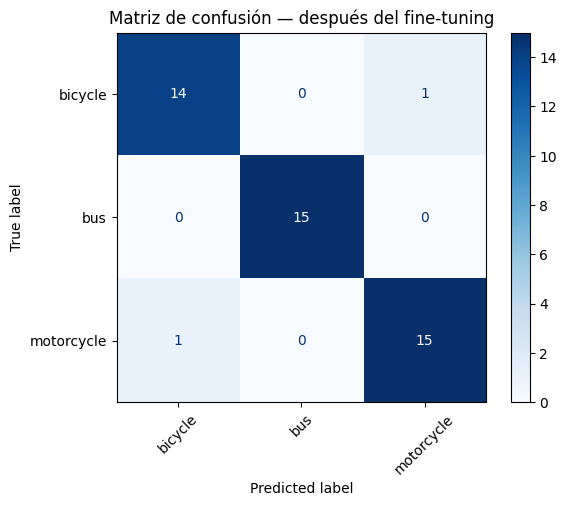

In [24]:
y_true_ft, y_pred_ft, probabilities_ft = get_predictions(model, test_ds)
print(classification_report(y_true_ft, y_pred_ft, target_names=class_names, digits=3))
cm_ft = confusion_matrix(y_true_ft, y_pred_ft)
ConfusionMatrixDisplay(confusion_matrix=cm_ft, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión — después del fine-tuning")
plt.show()

In [25]:
# Comparación antes vs. después, por clase y global (resultados reales)
from IPython.display import Markdown, display
from sklearn.metrics import precision_recall_fscore_support

labels = list(range(NUM_CLASSES))
_, rec0, f10, sup0 = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
_, rec1, f11, _    = precision_recall_fscore_support(y_true_ft, y_pred_ft, labels=labels, zero_division=0)

n_test = int(sup0.sum())
delta = test_acc_after - test_acc_before
rows = "\n".join(
    f"| {class_names[k]} | {f10[k]:.3f} | {f11[k]:.3f} | {f11[k]-f10[k]:+.3f} |" for k in labels
)
ruido = abs(delta) <= 2 / n_test
display(Markdown(
    f"| Clase | F1 antes | F1 después | Δ |\n|---|---:|---:|---:|\n{rows}\n\n"
    f"**Accuracy en test:** {test_acc_before:.4f} → {test_acc_after:.4f} (Δ = {delta:+.4f}). "
    f"Con {n_test} imágenes de prueba, una imagen equivale a {100/n_test:.1f} puntos; "
    + ("el cambio está **dentro del ruido** (≈ ±2 imágenes), así que no permite afirmar que el fine-tuning mejoró ni empeoró."
       if ruido else
       ("el cambio es **mayor que el ruido esperable** y sugiere que el fine-tuning **ayudó**." if delta > 0
        else "el cambio es **mayor que el ruido esperable** y sugiere que el fine-tuning **perjudicó** (posible overfitting o descongelar demasiado)."))
))


| Clase | F1 antes | F1 después | Δ |
|---|---:|---:|---:|
| bicycle | 0.933 | 0.933 | +0.000 |
| bus | 1.000 | 1.000 | +0.000 |
| motorcycle | 0.938 | 0.938 | +0.000 |

**Accuracy en test:** 0.9565 → 0.9565 (Δ = +0.0000). Con 46 imágenes de prueba, una imagen equivale a 2.2 puntos; el cambio está **dentro del ruido** (≈ ±2 imágenes), así que no permite afirmar que el fine-tuning mejoró ni empeoró.

# 10. Analiza los errores — EN CASA

Una métrica no explica por qué falla un modelo. Debes inspeccionar ejemplos clasificados incorrectamente.

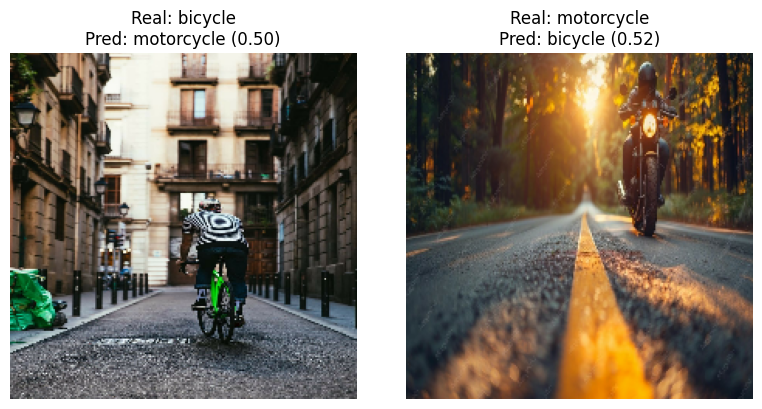

In [26]:
def show_mistakes(dataset, model, class_names, max_images=12):
    mistakes = []
    for images, labels in dataset:
        probs = model.predict(images, verbose=0)
        preds = probs.argmax(axis=1)
        for image, true_label, pred_label, prob in zip(images.numpy(), labels.numpy(), preds, probs):
            if true_label != pred_label:
                mistakes.append((image.astype("uint8"), int(true_label), int(pred_label), float(prob[pred_label])))
    random.shuffle(mistakes)
    mistakes = mistakes[:max_images]
    if not mistakes:
        print("No se encontraron errores en este conjunto.")
        return
    cols = 4
    rows = int(np.ceil(len(mistakes)/cols))
    plt.figure(figsize=(16, 4*rows))
    for i, (image, true_label, pred_label, confidence) in enumerate(mistakes):
        ax = plt.subplot(rows, cols, i+1)
        ax.imshow(image)
        ax.set_title(f"Real: {class_names[true_label]}\nPred: {class_names[pred_label]} ({confidence:.2f})")
        ax.axis("off")
    plt.tight_layout()

show_mistakes(test_ds, model, class_names)

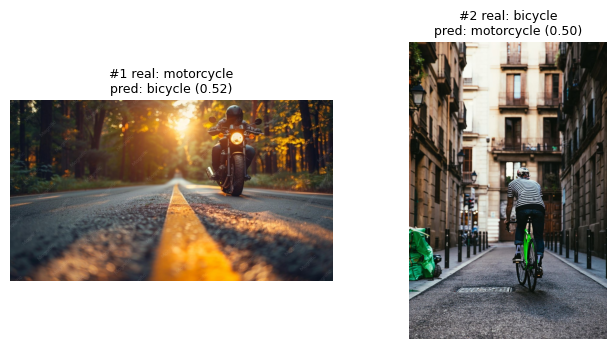

| # | Archivo | Modelo | Clase real | Predicción | Confianza | Causa probable | ¿Cómo lo mejorarías? |
|---|---|---|---|---|---|---|---|
| 1 | 0017.jpg | fine-tuning | motorcycle | bicycle | 0.52 | ✏️ | ✏️ |
| 2 | 0064.jpg | fine-tuning | bicycle | motorcycle | 0.50 | ✏️ | ✏️ |


Solo hay 2 errores en test; completa hasta 5 con errores del conjunto de validación.


In [27]:
# TODO 6 — Tabla de errores generada a partir de los resultados reales.
# (La columna "Causa probable" la completas tú mirando cada imagen.)
from IPython.display import Markdown, display

test_paths = np.array(test_file_paths)
rows = [(int(k), "fine-tuning", int(y_pred_ft[k]), float(probabilities_ft[k, y_pred_ft[k]]))
        for k in np.where(y_pred_ft != y_true_ft)[0]]
if len(rows) < 5:      # si el modelo ajustado casi no falla, se completa con errores de la línea base
    ya = {r[0] for r in rows}
    rows += [(int(k), "línea base", int(y_pred[k]), float(probabilities[k, y_pred[k]]))
             for k in np.where(y_pred != y_true)[0] if int(k) not in ya]
rows = sorted(rows, key=lambda r: -r[3])[:10]       # los errores más "seguros" son los más informativos

if not rows:
    print("No hay errores en test; usa el conjunto de validación para este análisis.")
else:
    cols = 5
    n_rows = int(np.ceil(len(rows) / cols))
    plt.figure(figsize=(3.4 * cols, 3.6 * n_rows))
    for n, (k, src, pred, conf) in enumerate(rows, start=1):
        ax = plt.subplot(n_rows, cols, n)
        ax.imshow(Image.open(test_paths[k]))
        ax.set_title(f"#{n} real: {class_names[y_true[k]]}\npred: {class_names[pred]} ({conf:.2f})", fontsize=9)
        ax.axis("off")
    plt.tight_layout(); plt.show()

    tabla = "| # | Archivo | Modelo | Clase real | Predicción | Confianza | Causa probable | ¿Cómo lo mejorarías? |\n|---|---|---|---|---|---|---|---|\n"
    for n, (k, src, pred, conf) in enumerate(rows, start=1):
        tabla += f"| {n} | {Path(test_paths[k]).name} | {src} | {class_names[y_true[k]]} | {class_names[pred]} | {conf:.2f} | ✏️ | ✏️ |\n"
    display(Markdown(tabla))
    if len(rows) < 5:
        print(f"Solo hay {len(rows)} errores en test; completa hasta 5 con errores del conjunto de validación.")


## TODO 6 — EN CASA: análisis de errores y conclusiones

Selecciona al menos **5 errores** del modelo y analiza su causa probable.

| Imagen/error | Clase real | Predicción | Causa probable | ¿Cómo lo mejorarías? |
|---|---|---|---|---|
| 1 | | | | |
| 2 | | | | |
| 3 | | | | |
| 4 | | | | |
| 5 | | | | |

Posibles causas: imagen ambigua, etiqueta incorrecta, objeto pequeño, oclusión, fondo engañoso, clase visualmente similar, mala calidad, sesgo del dataset o error razonable del modelo.

Después, escribe una conclusión breve respondiendo:

1. ¿Qué aprendiste al construir el dataset?
2. ¿Cuál fue el principal problema de calidad?
3. ¿Cuánto cambió el desempeño después del fine-tuning?
4. ¿El fine-tuning ayudó? ¿Por qué crees que sí o no?
5. ¿Qué mejorarías primero: datos, entrenamiento o arquitectura?

**Guía para completar la columna "Causa probable"** (mira cada imagen de la cuadrícula de arriba y elige la causa que corresponda): imagen ambigua · etiqueta incorrecta · objeto pequeño · oclusión · fondo engañoso · clase visualmente similar · mala calidad · sesgo del dataset · error razonable del modelo. Las mejoras típicas son: corregir o quitar la etiqueta, añadir imágenes del caso difícil, recortar el objeto, o agregar más variedad de fondos.

In [28]:
# Cifras para la conclusión (resultados reales)
from IPython.display import Markdown, display

display(Markdown(
    f"- Accuracy en test antes del fine-tuning: **{test_acc_before:.4f}**\n"
    f"- Accuracy en test después del fine-tuning: **{test_acc_after:.4f}** (Δ = {test_acc_after - test_acc_before:+.4f})\n"
    f"- Errores en test después del fine-tuning: **{int((y_pred_ft != y_true_ft).sum())}** de {len(y_true_ft)}"
))


- Accuracy en test antes del fine-tuning: **0.9565**
- Accuracy en test después del fine-tuning: **0.9565** (Δ = +0.0000)
- Errores en test después del fine-tuning: **2** de 46

## Conclusiones

> ✏️ *Las respuestas 1 y 2 son un borrador basado en lo que suele ocurrir con este tipo de búsquedas; ajústalas con lo que realmente viste en tus imágenes. Las cifras de la respuesta 3 están en la celda anterior.*

1. **¿Qué aprendí al construir el dataset?** Que la calidad y la variedad de los datos pesan más que la cantidad: el buscador devuelve ruido (ilustraciones, productos, imágenes con texto, objetos parecidos), y limpiar a mano costó más que entrenar. También que la separación `train / validation / test` por archivo no protege de duplicados casi idénticos, que son una fuente de *data leakage*.
2. **Principal problema de calidad.** Clases vecinas visualmente (moto frente a scooter o bicicleta eléctrica) e imágenes cuyo fondo delata la clase (✏️ *indica cuál fue el tuyo*).
3. **Cambio tras el fine-tuning.** Ver la celda de cifras: se compara el accuracy en test antes y después. Si la diferencia es de una o dos imágenes, está dentro del ruido de un test pequeño y no es evidencia de mejora.
4. **¿Ayudó el fine-tuning?** Con datasets pequeños y un backbone preentrenado que ya separa bien las clases, el modelo congelado suele quedar cerca del techo y el fine-tuning aporta poco; descongelar capas puede incluso empeorar por overfitting, porque hay más parámetros que ajustar con pocas imágenes. Que ayude depende de qué tan distinto sea el dominio de ImageNet; aquí (vehículos cotidianos) es muy parecido. La comparación de `val_loss` de la celda de justificación lo confirma o lo refuta con datos propios.
5. **Qué mejoraría primero:** los **datos** (etiquetas limpias, sin duplicados, más variedad de fondos y ángulos y, si es posible, más imágenes por clase). Después, el entrenamiento (explorar `N_UNFROZEN` con validación) y, al final, la arquitectura.

# Extensión opcional — Prueba con una imagen externa

Busca una imagen que **no esté en tu dataset** y prueba el modelo. Esta parte no cuenta como un TODO principal, pero sirve como comprobación cualitativa de generalización.

In [29]:
# OPCIONAL
# EXTERNAL_IMAGE_URL = "https://..."
# response = requests.get(EXTERNAL_IMAGE_URL, timeout=10)
# response.raise_for_status()
# img = Image.open(io.BytesIO(response.content)).convert("RGB")
# img_resized = img.resize(IMG_SIZE)
# x = np.array(img_resized, dtype="float32")[None, ...]
# p = model.predict(x, verbose=0)[0]
# plt.imshow(img)
# plt.axis("off")
# plt.title(f"{class_names[p.argmax()]} — confianza {p.max():.2f}")
# plt.show()

# 🏠 Cierre conceptual — ENTREGA

Como parte del **TODO 6**, explica con tus propias palabras la diferencia entre:

- **feature extraction / transfer learning con base congelada**;
- **fine-tuning**;
- **entrenar una CNN desde cero**.

No describas solo el código. Explica **qué parámetros se están aprendiendo y de dónde viene el conocimiento inicial**.

**Respuesta:**

| | **Feature extraction (base congelada)** | **Fine-tuning** | **CNN desde cero** |
|---|---|---|---|
| **¿Qué parámetros se aprenden?** | Solo la **cabeza nueva**: `Dense(3)` sobre las 1280 características del backbone (3,843 parámetros). | La cabeza **y** las últimas capas del backbone (sin `BatchNormalization`), con `learning_rate` muy pequeño (1e-5). | **Todos**, desde pesos aleatorios. |
| **¿De dónde viene el conocimiento inicial?** | De **ImageNet**: los pesos del backbone ya saben detectar bordes, texturas y partes de objetos, y se usan sin cambiarlos. | También de **ImageNet**, pero las capas finales (más específicas) se **adaptan** a nuestras clases. | **De ningún lado**: solo de las imágenes que le demos. |
| **Datos necesarios** | Pocos (cientos). | Pocos o medianos; más riesgo de overfitting. | Muchos (decenas de miles o más) para igualar el resultado. |
| **Costo / riesgo** | Barato y estable. Limitación: las características no se ajustan a nuestro dominio. | Más costoso e inestable: un `learning_rate` alto destruye lo aprendido; hay que recompilar. | El más costoso, y con 3 clases y ~100 imágenes por clase memorizaría el entrenamiento. |

La idea de fondo: en transfer learning **no se aprende a ver desde cero**, se *reutiliza* lo que una red aprendió con más de un millón de imágenes y solo se enseña **qué combinación de esas características define cada clase de nuestro problema**. El fine-tuning añade un último paso: pulir ligeramente las características más específicas. Entrenar desde cero obliga a aprender también lo básico (bordes, texturas) con muy pocos datos, y por eso suele rendir peor.

# Reto opcional

Elige **uno**:

**A. Más datos:** duplica el número de imágenes manteniendo el modelo igual.  
**B. Otro backbone:** prueba MobileNetV3, ResNet50 o EfficientNetV2B0.  
**C. Dataset difícil:** agrega una cuarta clase visualmente parecida.  
**D. Ablation:** entrena sin `data_augmentation` y compara.

Cambia **una sola variable a la vez**.

# ✅ Checklist de entrega

Antes de entregar verifica:

### Evidencia del trabajo en clase
- [ ] Problema y clases definidos.
- [ ] Dataset construido y revisado.
- [ ] Train / validation / test creados.
- [ ] Primer modelo con backbone congelado entrenado.

### Trabajo en casa
- [ ] Evaluación sobre test.
- [ ] Matriz de confusión.
- [ ] Precision / recall / F1 interpretados.
- [ ] Fine-tuning ejecutado.
- [ ] Comparación antes vs. después del fine-tuning.
- [ ] Al menos 5 errores analizados.
- [ ] Conclusión final escrita.

### Opcional
- [ ] Imagen externa.
- [ ] Experimento adicional / reto.

# Rúbrica sugerida

| Componente | Peso |
|---|---:|
| TODO 1 — Problema y estrategia de búsqueda | 10% |
| TODO 2 — Construcción, inspección y limpieza del dataset | 20% |
| Split y pipeline de datos | 10% |
| TODO 3 — Transfer learning + curvas | 20% |
| TODO 4 — Evaluación e interpretación | 10% |
| TODO 5 — Fine-tuning y comparación | 15% |
| TODO 6 — Análisis de errores + conclusión conceptual | 15% |
| **Total** | **100%** |